In [22]:
import pandas as pd 
import numpy as np
from sklearn.preprocessing import StandardScaler,RobustScaler
from sklearn.impute import SimpleImputer,KNNImputer,KNNImputer
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns



In [23]:


df = pd.read_csv("stroke_zaj1.csv",sep=';')


## dane intro 

- response variable to stroke

In [24]:
df

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67,0,1,Yes,Private,Urban,"228,69","36,6",formerly smoked,1
1,Male,80,0,1,Yes,Private,Rural,"105,92","32,5",never smoked,1
2,Female,49,0,0,Yes,Private,NaN,"171,23","34,4",smokes,1
3,Female,79,1,0,Yes,Self-employed,Rural,"174,12",24,never smoked,1
4,Male,81,0,0,Yes,Private,Urban,"186,21",29,formerly smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
607,Male,48,0,0,Yes,Private,Rural,NaN,"34,6",never smoked,0
608,Female,62,0,0,Yes,Private,Urban,"60,2","27,7",formerly smoked,0
609,Male,69,1,0,No,NaN,Urban,"75,95","28,6",never smoked,0
610,Female,54,0,0,Yes,Private,Urban,"75,09","38,9",formerly smoked,0


In [25]:
df.shape



(612, 11)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   gender             612 non-null    str  
 1   age                612 non-null    int64
 2   hypertension       612 non-null    int64
 3   heart_disease      612 non-null    int64
 4   ever_married       612 non-null    str  
 5   work_type          557 non-null    str  
 6   Residence_type     552 non-null    str  
 7   avg_glucose_level  568 non-null    str  
 8   bmi                549 non-null    str  
 9   smoking_status     612 non-null    str  
 10  stroke             612 non-null    int64
dtypes: int64(4), str(7)
memory usage: 52.7 KB


In [27]:
df.describe()


,age,hypertension,heart_disease,stroke
count,612.000000,612.000000,612.000000,612.000000
mean,52.632353,0.158497,0.096405,0.341503
std,20.709916,0.365505,0.295388,0.474602
min,5.000000,0.000000,0.000000,0.000000
25%,39.000000,0.000000,0.000000,0.000000
50%,54.000000,0.000000,0.000000,0.000000
75%,70.000000,0.000000,0.000000,1.000000
max,82.000000,1.000000,1.000000,1.000000


In [ ]:
 
for col in ["bmi", "avg_glucose_level"]: # zmiana na numeric ponieważ wcześniej te kolumny były wczytane jako string 
    df[col] = pd.to_numeric( 
        df[col].str.replace(",", ".", regex=False),
        errors="coerce"
    )

In [29]:
df.dtypes


gender                   str
age                    int64
hypertension           int64
heart_disease          int64
ever_married             str
work_type                str
Residence_type           str
avg_glucose_level    float64
bmi                  float64
smoking_status           str
stroke                 int64
dtype: object

In [30]:

df.isna().sum()



gender                0
age                   0
hypertension          0
heart_disease         0
ever_married          0
work_type            55
Residence_type       60
avg_glucose_level    44
bmi                  63
smoking_status        0
stroke                0
dtype: int64

## krótki opis danych


- Zbiór danych zawiera **612 obserwacji i 11 zmiennych**, z czego 10 to zmienne objaśniające, a `stroke` jest zmienną objaśnianą, określającą wystąpienie udaru mózgu.

- W zbiorze występują zmienne numeryczne (m.in. wiek, BMI, poziom glukozy), binarne (nadciśnienie, choroby serca) oraz kategoryczne (płeć, rodzaj pracy, miejsce zamieszkania, stan cywilny i status palenia).

- Średni wiek badanych wynosi około 52,6 lat, a **34,15% obserwacji dotyczy osób, u których wystąpił udar**. Brakujące wartości występują w czterech zmiennych: `work_type`, `Residence_type`, `avg_glucose_level` i `bmi`.

- Dodatkowo zmienne `bmi` i `avg_glucose_level` zostały przekonwertowane z typu tekstowego na numeryczny (`float64`), aby umożliwić ich dalszą analizę i imputację.



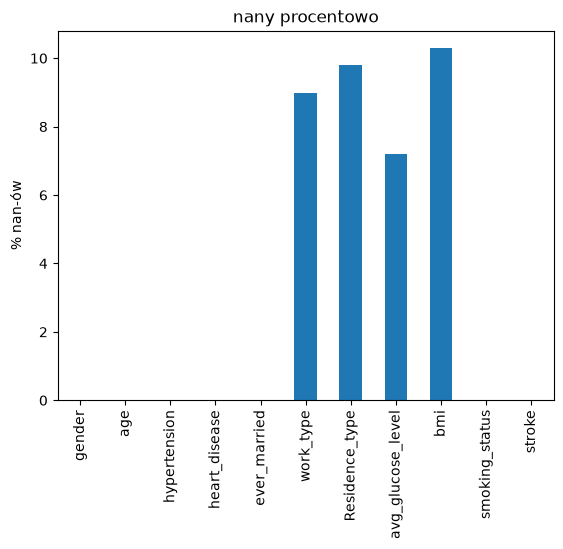

In [31]:
(df.isna().mean() * 100).round(2).plot(kind='bar') # y axis to są procenty 

plt.title("nany procentowo")

plt.ylabel("% nan-ów")

plt.show()

- Brakujące wartości występują w czterech zmiennych: `bmi` (10,3%), `Residence_type` (9,8%), `work_type` (9,0%) oraz `avg_glucose_level` (7,2%). 

- W pozostałych zmiennych nie odnotowano braków danych. Ze względu na stosunkowo niewielki udział braków zdecydowano się zastosować różne metody imputacji zamiast usuwać obserwacje.

## podzial danych 

In [32]:

X = df.drop(columns=["stroke"])
y = df["stroke"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,  test_size=0.2, random_state=42, stratify=y )

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

In [33]:

print(f"Test: ---> {y_train.value_counts(normalize=True)}  ") 

print(f"Test: ---> {y_test.value_counts(normalize=True)}  ")

Test: ---> stroke
0    0.658487
1    0.341513
Name: proportion, dtype: float64  
Test: ---> stroke
0    0.658537
1    0.341463
Name: proportion, dtype: float64  


- podział danych klasy y jest +- równy, dlatego używamy stratify ( bez niej proporcji podzialu nie kontrolujemy i będą split-dependent)

## Imputowanie zmiennych przed i po

In [34]:


def impute_data(X_train, X_test, method="median"):
    """
     - Funckja dod imputowania danych zamiast powtarzać kod 3 razy ręcznie 

    """
    
    train = X_train.copy()
    test = X_test.copy()
    
    num_cols = train.select_dtypes(include="number").columns.tolist()
    cat_cols = train.select_dtypes(exclude="number").columns.tolist()

    if method == "knn": # KNN + SKALOWANIE
        scaler = StandardScaler()

        train_scaled = scaler.fit_transform(train[num_cols])
        test_scaled = scaler.transform(test[num_cols])

        imputer = KNNImputer(n_neighbors=5) # HEURISTIC ASSUMPTION 

        train[num_cols] = scaler.inverse_transform( imputer.fit_transform(train_scaled) )
        
        test[num_cols] = scaler.inverse_transform( imputer.transform(test_scaled) )

    else: # PLAIN VANILLA  
        imputer = SimpleImputer(strategy=method)

        train[num_cols] = imputer.fit_transform(train[num_cols])
        test[num_cols] = imputer.transform(test[num_cols])

    # jesli istnieje jakas categorical to impute most frequent
    if cat_cols:
        cat_imputer = SimpleImputer(strategy="most_frequent")

        train[cat_cols] = cat_imputer.fit_transform(train[cat_cols])
        test[cat_cols] = cat_imputer.transform(test[cat_cols])

    return train, test

In [35]:
X_train_mean, X_test_mean = impute_data(
    X_train, X_test, method="mean"
)

# Mediana
X_train_median, X_test_median = impute_data(
    X_train, X_test, method="median"
)

# KNN
X_train_knn, X_test_knn = impute_data(
    X_train, X_test, method="knn"
)

In [37]:
datasets = {
    "Before": X_train,
    "Mean": X_train_mean,
    "Median": X_train_median,
    "KNN": X_train_knn
}

stats = pd.concat({
    name: data[num_cols].agg(
        ["mean", "median", "std", "min", "max", "skew","kurtosis"]
    ).T
    for name, data in datasets.items()
})

display(stats)

mean     median        std    min     max  \
Before age                 52.417178  54.000000  20.904001   5.00   82.00   
       hypertension         0.157464   0.000000   0.364611   0.00    1.00   
       heart_disease        0.098160   0.000000   0.297835   0.00    1.00   
       avg_glucose_level  117.192193  96.100000  54.355124  55.39  271.74   
       bmi                 30.632877  29.400000   7.132330  14.60   56.60   
Mean   age                 52.417178  54.000000  20.904001   5.00   82.00   
       hypertension         0.157464   0.000000   0.364611   0.00    1.00   
       heart_disease        0.098160   0.000000   0.297835   0.00    1.00   
       avg_glucose_level  117.192193  98.660000  52.485130  55.39  271.74   
       bmi                 30.632877  30.632877   6.749354  14.60   56.60   
Median age                 52.417178  54.000000  20.904001   5.00   82.00   
       hypertension         0.157464   0.000000   0.364611   0.00    1.00   
       heart_disease        0.098160   0.000000   0.297835   0.00    1.00   
       avg_glucose_level  115.768793  96.100000  52.751709  55.39  271.74   
       bmi                 30.504294  29.400000   6.759887  14.60   56.60   
KNN    age                 52.417178  54.000000  20.904001   5.00   82.00   
       hypertension         0.157464   0.000000   0.364611   0.00    1.00   
       heart_disease        0.098160   0.000000   0.297835   0.00    1.00   
       avg_glucose_level  117.625865  98.050000  53.047017  55.39  271.74   
       bmi                 30.589325  29.500000   6.842206  14.60   56.60   

                              skew  kurtosis  
Before age               -0.393311 -0.833332  
       hypertension       1.886628  1.565751  
       heart_disease      2.709493  5.363271  
       avg_glucose_level  1.166858  0.079976  
       bmi                0.718962  0.525592  
Mean   age               -0.393311 -0.833332  
       hypertension       1.886628  1.565751  
       heart_disease      2.709493  5.363271  
       avg_glucose_level  1.208073  0.303188  
       bmi                0.759395  0.935958  
Median age               -0.393311 -0.833332  
       hypertension       1.886628  1.565751  
       heart_disease      2.709493  5.363271  
       avg_glucose_level  1.266812  0.371732  
       bmi                0.812519  0.971619  
KNN    age               -0.393311 -0.833332  
       hypertension       1.886628  1.565751  
       heart_disease      2.709493  5.363271  
       avg_glucose_level  1.164328  0.156194  
       bmi                0.734535  0.777725

## rozkłady przed i po imputation

In [48]:

def compare_distributions(before, after):

    cols = ["bmi", "avg_glucose_level"]

    df = pd.concat([
        before[cols].assign(Method="Before"), after[cols].assign(Method="After KNN")
    ])

    df = df.melt(
        id_vars="Method", var_name="Variable", value_name="Value"
    )

    sns.displot(
        data=df,
        x="Value",
        hue="Method",
        col="Variable",
        kind="hist",
         kde=True, stat="density",
        common_norm=False,
        alpha=0.4,
         height=4,
        aspect=1.3,
         facet_kws={"sharex": False, "sharey": False}
    )
    
    plt.show()

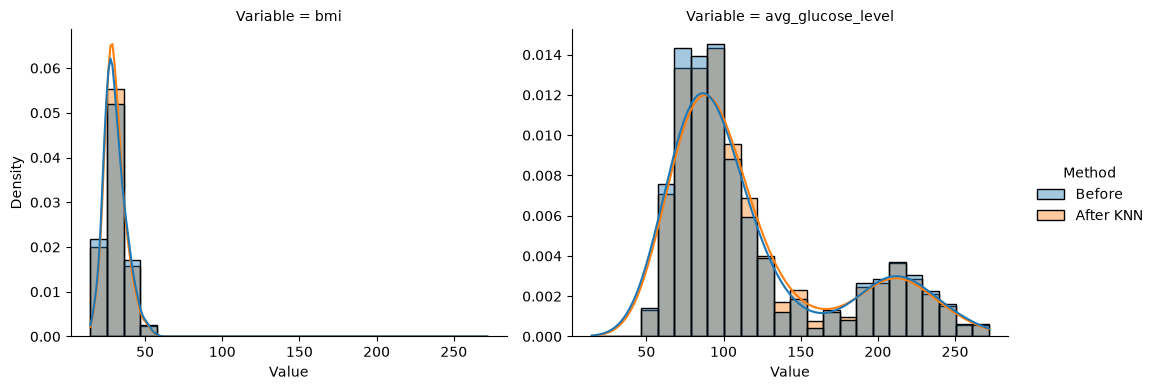

In [ ]:
compare_distributions(X_train, X_train_knn)

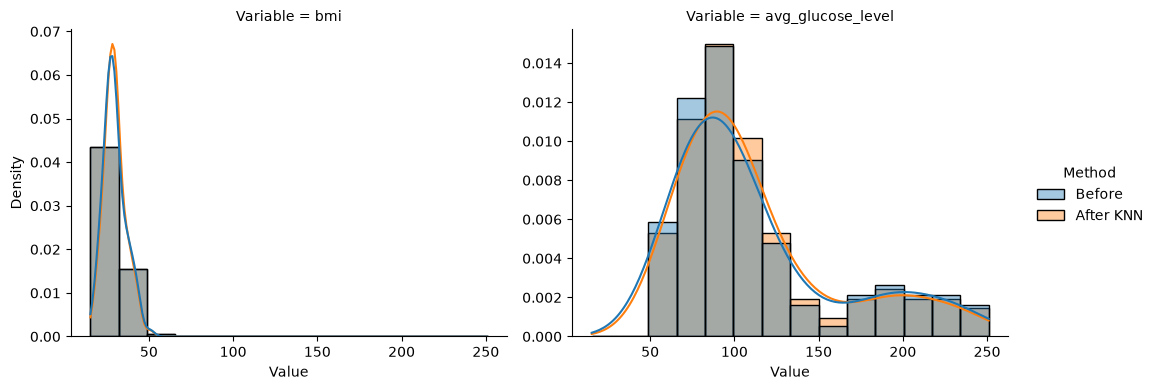

In [50]:
compare_distributions(X_test, X_test_knn)

Po imputacji rozkłady zmiennych ulegly niewielkim zmianom głownie dla BMI i średniego poziomu glukozy.

- Mean: zachowuje średnią, ale zmniejsza odchylenie standardowe.
- Median: zachowuje medianę, ale nieznacznie zmienia średnią oraz zwiększa skośność i kurtozę, szczególnie dla BMI.
- KNN: lepiej zachowuje zmienność danych i powoduje mniejsze zmiany skośności.

Ogólnie , zmiany w rozkładach były stosunkowo niewielkie. Na podstawie przedstawionych statystyk KNN najlepiej zachował charakterystyki oryginalnych rozkładów.

- z tego powodu w do fitowania modelu użyjemy KNN - imputation

- NEXT TO BE DONE Określić typ danych i zastanowić się czy konieczne jest wykonanie
pewnych przekształceń. Podzielić dane na zbiór uczący i testowy.


# Odpowiedz na pytania pomocnicze 

## 1

### Podział danych na zbiór uczący i testowy
- Train - służy do trenowania modelu.
- Test - służy do oceny modelu na nowych danych.
- Cel: -sprawdzenie zdolności modelu do generalizacji i ograniczenie ryzyka overfittingu. Najczęściej stosuje się podział 80/20 albo 70/30.


## 2

### Macierz błędu (Confusion Matrix)
Pokazuje liczbę poprawnych i błędnych klasyfikacji:
- TP – poprawnie wykryty udar.
- TN – poprawnie wykryty brak udaru.
- FP – fałszywy alarm.
- FN – niewykryty udar.

## 3

### Miary jakości klasyfikacji
- Accuracy – udział wszystkich poprawnych predykcji: (TP+TN)/(TP+TN+FP+FN).
- Sensitivity (Recall) – udział poprawnie wykrytych udarów: TP/(TP+FN).
- Specificity - udział poprawnie rozpoznanych osób bez udaru: TN/(TN+FP).
- Precision - udział rzeczywistych udarów wśród przewidzianych: TP/(TP+FP).
- F1-score - średnia harmoniczna Precision i Recall. 2 * precision * recall / ( precision + recall)
- ROC-AUC - zdolność modelu do rozróżniania klas przy różnych progach.

- Najważniejsza miara: w przypadku przewidywania udaru szczególnie istotna jest **czułość (Recall)**, ponieważ niewykrycie udaru (FN) może mieć poważniejsze konsekwencje niż fałszywy alarm (FP).

# KNN 

In [51]:
X_train

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
336,Male,42,0,0,Yes,Private,NaN,145.50,31.8,formerly smoked
427,Female,57,0,0,Yes,Private,Rural,93.85,29.1,never smoked
211,Male,40,0,0,Yes,Private,Rural,56.07,26.6,never smoked
483,Male,36,0,0,Yes,Private,Rural,106.85,40.1,never smoked
101,Female,58,0,0,Yes,Private,Rural,59.86,28.0,formerly smoked
...,...,...,...,...,...,...,...,...,...,...
509,Female,40,0,0,Yes,Private,Urban,153.24,38.2,Unknown
186,Male,49,0,0,No,Private,NaN,104.86,31.9,smokes
161,Male,70,1,0,Yes,Private,Rural,242.52,45.5,formerly smoked
570,Female,25,0,0,Yes,Private,Rural,90.65,20.9,Unknown


In [52]:
X_test

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
280,Male,39,0,0,Yes,Self-employed,Rural,88.48,34.3,never smoked
370,Male,63,0,0,Yes,Private,Rural,77.82,30.3,Unknown
557,Female,13,0,0,No,children,Rural,69.01,23.4,Unknown
117,Male,82,0,1,Yes,Govt_job,Rural,103.68,25.0,never smoked
21,Male,80,0,0,Yes,Self-employed,Rural,104.12,NaN,never smoked
...,...,...,...,...,...,...,...,...,...,...
192,Female,79,0,0,Yes,NaN,Urban,97.73,21.5,smokes
88,Female,50,1,0,Yes,NaN,Rural,73.18,30.3,formerly smoked
75,Female,57,0,0,No,Self-employed,Urban,68.02,37.5,never smoked
466,Male,80,0,0,Yes,Private,Rural,56.99,26.7,never smoked


In [53]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", KNNImputer(n_neighbors=5))
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsClassifier())
])

In [54]:
param_grid = {
    "knn__n_neighbors": range(1, 31)
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "recall": "recall",
        "balanced_accuracy": "balanced_accuracy",
        "f1": "f1"
    },
    refit="balanced_accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best k:", grid.best_params_)
print("Best CV score:", grid.best_score_)

Best k: {'knn__n_neighbors': 15}
Best CV score: 0.7032504199232141


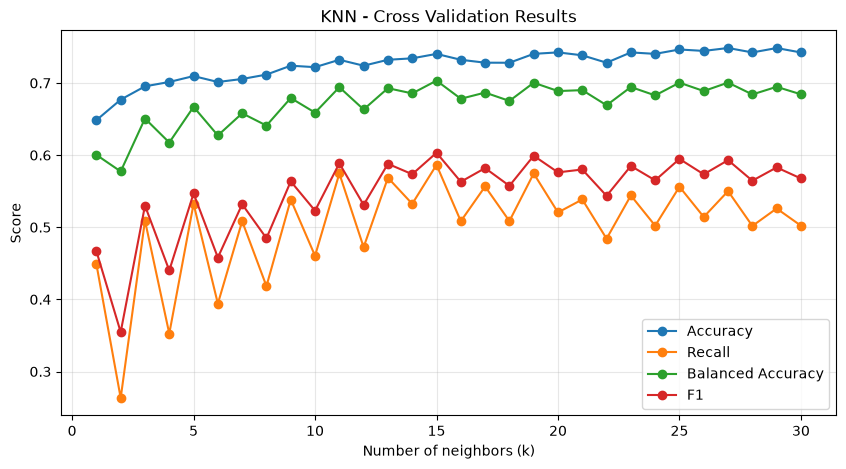

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame(grid.cv_results_)

metrics = [
    "mean_test_accuracy",
    "mean_test_recall",
    "mean_test_balanced_accuracy",
    "mean_test_f1"
]

results.set_index("param_knn__n_neighbors")[metrics].plot(
    figsize=(10, 5),
    marker="o"
)

plt.xlabel("Number of neighbors (k)")
plt.ylabel("Score")
plt.title("KNN - Cross Validation Results")
plt.legend(["Accuracy", "Recall", "Balanced Accuracy", "F1"])
plt.grid(alpha=0.3)
plt.show()

              precision    recall  f1-score   support

           0       0.80      0.79      0.80        81
           1       0.60      0.62      0.61        42

    accuracy                           0.73       123
   macro avg       0.70      0.70      0.70       123
weighted avg       0.73      0.73      0.73       123



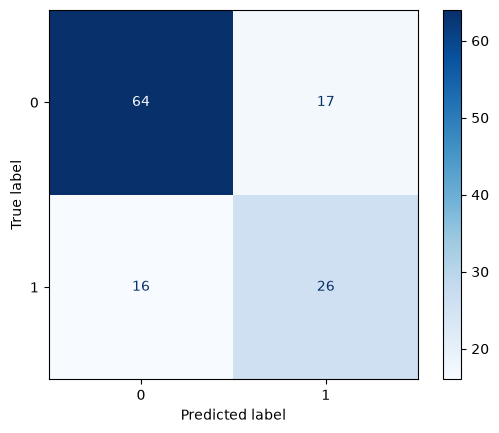

In [56]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap="Blues"
)

plt.show()

## odpowiedź na pytania teoretyczne 

# KNN -WEIGHTED

## odpowiedź na pytania teoretyczne 

# LOGISTYCZNA REGRESJA  

## odpowiedź na pytania teoretyczne 